# IDS Model Retraining — V2
## Targeting Better Generalisation and Calibrated Confidence

**Issues with V1 model:**
- Aggressive feature selection (57→15) lost discriminative signal
- SMOTETomek introduced synthetic samples that didn't match real distributions
- Threshold tuning prioritised recall, destroying precision (Infiltration: 0.04, LowSev: 0.11)

**V2 strategy:**
- Use **all features** — let regularisation handle redundancy
- **class_weight='balanced'** instead of SMOTETomek — no synthetic data drift
- Stratified subsampling to manage data size (capped per class)
- **F1-optimised threshold tuning** (not recall-only)
- Per-class precision-recall analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json, pickle, os, warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    classification_report, confusion_matrix,
    f1_score, ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight

from xgboost import XGBClassifier
import tensorflow as tf
from keras import layers, regularizers, callbacks

os.makedirs('plots_v2', exist_ok=True)
print('Setup complete.')

Setup complete.


## 1. Load Pre-Processed Data

In [2]:
df = pd.read_csv('Dataset/ProcessedData.csv')
print(f'Loaded: {df.shape}')
print(f'\nClass distribution:')
print(df['Attack_Group'].value_counts())

Loaded: (9167220, 58)

Class distribution:
Attack_Group
Normal               7185841
DDoS                 1234722
DoS                   397338
Botnet                145968
BruteForce            105264
Infiltration           94857
LowSeverityAttack       3230
Name: count, dtype: int64


## 2. Stratified Subsampling

**Justification:** 9.1M rows is excessive. We cap each class at 200K samples — keeping all rare class samples (Infiltration, LowSev, etc. since they have <200K) and downsampling the majority classes. This preserves natural imbalance which class_weight handles properly.

In [3]:
MAX_PER_CLASS = 200000

balanced = []
for cls in df['Attack_Group'].unique():
    sub = df[df['Attack_Group'] == cls]
    if len(sub) > MAX_PER_CLASS:
        sub = sub.sample(n=MAX_PER_CLASS, random_state=42)
    balanced.append(sub)

df_bal = pd.concat(balanced).sample(frac=1, random_state=42).reset_index(drop=True)

print(f'Subsampled: {df_bal.shape}')
print(f'\nNew distribution:')
print(df_bal['Attack_Group'].value_counts())

Subsampled: (949319, 58)

New distribution:
Attack_Group
Normal               200000
DoS                  200000
DDoS                 200000
Botnet               145968
BruteForce           105264
Infiltration          94857
LowSeverityAttack      3230
Name: count, dtype: int64


## 3. Light Feature Pruning Only

**Justification:** Instead of aggressive selection (which threw away signal in V1), we only remove features with literal zero variance. We keep everything else and let XGBoost's internal feature importance + L1/L2 regularisation handle redundancy.

In [4]:
X_all = df_bal.drop(columns=['Attack_Group']).reset_index(drop=True)
y_all = df_bal['Attack_Group'].reset_index(drop=True)

vt = VarianceThreshold(threshold=0.0)
vt.fit(X_all)
kept_features = X_all.columns[vt.get_support()].tolist()
X = X_all[kept_features].reset_index(drop=True)

print(f'Original features: {X_all.shape[1]}')
print(f'Kept features:     {X.shape[1]}')
print(f'Removed (zero variance): {X_all.shape[1] - X.shape[1]}')

Original features: 57
Kept features:     57
Removed (zero variance): 0


## 4. Encode & Split (70/15/15)

In [5]:
le = LabelEncoder()
y = le.fit_transform(y_all)
label_map = dict(zip(le.classes_, le.transform(le.classes_)))
n_classes = len(le.classes_)
print('Label encoding:', label_map)

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.176, stratify=y_temp, random_state=42)

print(f'\nTrain: {X_train.shape}')
print(f'Val:   {X_val.shape}')
print(f'Test:  {X_test.shape}')

Label encoding: {'Botnet': np.int64(0), 'BruteForce': np.int64(1), 'DDoS': np.int64(2), 'DoS': np.int64(3), 'Infiltration': np.int64(4), 'LowSeverityAttack': np.int64(5), 'Normal': np.int64(6)}

Train: (664902, 57)
Val:   (142019, 57)
Test:  (142398, 57)


## 5. Class Weights (No Synthetic Data)

Compute balanced class weights and pass to loss function — standard, well-justified approach for imbalanced classification.

In [6]:
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = dict(zip(np.unique(y_train), class_weights))
for idx, w in class_weight_dict.items():
    print(f'  {le.classes_[idx]:<22} {w:.4f}')

sample_weights = np.array([class_weight_dict[yi] for yi in y_train])

  Botnet                 0.9291
  BruteForce             1.2884
  DDoS                   0.6781
  DoS                    0.6781
  Infiltration           1.4297
  LowSeverityAttack      41.9735
  Normal                 0.6781


In [7]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)
print('Scaling complete.')

Scaling complete.


## 6. XGBoost V2

In [8]:
xgb_model = XGBClassifier(
    n_estimators=600, max_depth=8, learning_rate=0.05,
    subsample=0.7, colsample_bytree=0.7,
    reg_alpha=0.2, reg_lambda=1.5,
    objective='multi:softprob', num_class=n_classes,
    tree_method='hist', eval_metric='mlogloss',
    early_stopping_rounds=30, n_jobs=-1, random_state=42
)

xgb_model.fit(
    X_train_s, y_train,
    sample_weight=sample_weights,
    eval_set=[(X_train_s, y_train), (X_val_s, y_val)],
    verbose=50
)
print(f'\nBest iteration: {xgb_model.best_iteration}')

[0]	validation_0-mlogloss:1.80314	validation_1-mlogloss:1.80314
[50]	validation_0-mlogloss:0.28121	validation_1-mlogloss:0.28256
[100]	validation_0-mlogloss:0.15634	validation_1-mlogloss:0.15866
[150]	validation_0-mlogloss:0.13076	validation_1-mlogloss:0.13395
[200]	validation_0-mlogloss:0.12036	validation_1-mlogloss:0.12482
[250]	validation_0-mlogloss:0.11421	validation_1-mlogloss:0.11990
[300]	validation_0-mlogloss:0.10972	validation_1-mlogloss:0.11668
[350]	validation_0-mlogloss:0.10624	validation_1-mlogloss:0.11454
[400]	validation_0-mlogloss:0.10323	validation_1-mlogloss:0.11282
[450]	validation_0-mlogloss:0.10076	validation_1-mlogloss:0.11160
[500]	validation_0-mlogloss:0.09860	validation_1-mlogloss:0.11064
[550]	validation_0-mlogloss:0.09669	validation_1-mlogloss:0.10983
[599]	validation_0-mlogloss:0.09493	validation_1-mlogloss:0.10918

Best iteration: 599


In [9]:
y_pred_xgb_val = xgb_model.predict(X_val_s)
print('=== XGBoost V2 — Validation ===')
print(classification_report(y_val, y_pred_xgb_val, target_names=le.classes_))

=== XGBoost V2 — Validation ===
                   precision    recall  f1-score   support

           Botnet       1.00      1.00      1.00     21837
       BruteForce       1.00      0.99      0.99     15748
             DDoS       1.00      1.00      1.00     29920
              DoS       1.00      1.00      1.00     29920
     Infiltration       0.66      0.94      0.78     14191
LowSeverityAttack       0.75      0.91      0.82       483
           Normal       0.96      0.77      0.86     29920

         accuracy                           0.94    142019
        macro avg       0.91      0.94      0.92    142019
     weighted avg       0.96      0.94      0.95    142019



## 7. DNN V2 — Wider with LeakyReLU

In [10]:
n_features = X_train_s.shape[1]

dnn_model = tf.keras.Sequential([
    layers.Dense(256, kernel_regularizer=regularizers.l2(1e-4), input_shape=(n_features,)),
    layers.LeakyReLU(0.1),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(128, kernel_regularizer=regularizers.l2(1e-4)),
    layers.LeakyReLU(0.1),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(64, kernel_regularizer=regularizers.l2(1e-4)),
    layers.LeakyReLU(0.1),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(32, kernel_regularizer=regularizers.l2(1e-4)),
    layers.LeakyReLU(0.1),
    layers.Dropout(0.2),
    layers.Dense(n_classes, activation='softmax')
])
dnn_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
dnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        14,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,103 (234.78 KB)

 Trainable params: 59,207 (231.28 KB)

 Non-trainable params: 896 (3.50 KB)

In [11]:
history = dnn_model.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),
    epochs=80, batch_size=2048,
    class_weight=class_weight_dict,
    callbacks=[
        callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6, verbose=1)
    ],
    verbose=1
)

Epoch 1/80
325/325 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.6738 - loss: 0.9076 - val_accuracy: 0.7900 - val_loss: 0.5606 - learning_rate: 0.0010
Epoch 2/80
325/325 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.7795 - loss: 0.5903 - val_accuracy: 0.8113 - val_loss: 0.4398 - learning_rate: 0.0010
Epoch 3/80
325/325 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7929 - loss: 0.5326 - val_accuracy: 0.8108 - val_loss: 0.4316 - learning_rate: 0.0010
Epoch 4/80
325/325 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8023 - loss: 0.4956 - val_accuracy: 0.8063 - val_loss: 0.4130 - learning_rate: 0.0010
Epoch 5/80
325/325 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8065 - loss: 0.4747 - val_accuracy: 0.8244 - val_loss: 0.3843 - learning_rate: 0.0010
Epoch 6/80
325/325 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8094 - loss: 0.4588 - val_accuracy: 0.8228 - val_loss: 0.3960 - learning_rate: 0.0010
Epoch 7/80
325/325 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8124 - loss: 0.

In [12]:
probs_dnn_val = dnn_model.predict(X_val_s, batch_size=2048, verbose=0)
y_pred_dnn_val = np.argmax(probs_dnn_val, axis=1)
print('=== DNN V2 — Validation ===')
print(classification_report(y_val, y_pred_dnn_val, target_names=le.classes_))

=== DNN V2 — Validation ===
                   precision    recall  f1-score   support

           Botnet       1.00      0.99      0.99     21837
       BruteForce       1.00      0.98      0.99     15748
             DDoS       0.99      0.98      0.98     29920
              DoS       0.95      0.99      0.97     29920
     Infiltration       0.44      0.91      0.60     14191
LowSeverityAttack       0.25      0.95      0.40       483
           Normal       0.94      0.41      0.57     29920

         accuracy                           0.86    142019
        macro avg       0.80      0.89      0.79    142019
     weighted avg       0.92      0.86      0.86    142019



## 8. Ensemble + F1-Optimal Threshold Tuning

In [13]:
probs_xgb_val = xgb_model.predict_proba(X_val_s)
ensemble_val = 0.6 * probs_xgb_val + 0.4 * probs_dnn_val

# Tune thresholds for ALL minority classes — F1-optimised
minority_classes = ['Infiltration', 'LowSeverityAttack', 'Botnet', 'BruteForce']
tuned_thresholds = {}

for cls_name in minority_classes:
    if cls_name not in label_map:
        continue
    cls_idx = label_map[cls_name]
    cls_probs = ensemble_val[:, cls_idx]
    y_binary = (y_val == cls_idx).astype(int)
    
    best_f1, best_t = 0, 0.5
    for t in np.arange(0.1, 0.9, 0.02):
        preds = (cls_probs > t).astype(int)
        if preds.sum() == 0:
            continue
        f1 = f1_score(y_binary, preds, zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    
    tuned_thresholds[cls_name] = {'idx': int(cls_idx), 'threshold': float(best_t), 'best_f1': float(best_f1)}
    print(f'{cls_name:<22} threshold={best_t:.3f} | F1={best_f1:.4f}')

Infiltration           threshold=0.580 | F1=0.7764
LowSeverityAttack      threshold=0.740 | F1=0.8248
Botnet                 threshold=0.420 | F1=0.9994
BruteForce             threshold=0.180 | F1=0.9948


## 9. Final Test Evaluation

In [14]:
probs_xgb_test = xgb_model.predict_proba(X_test_s)
probs_dnn_test = dnn_model.predict(X_test_s, batch_size=2048, verbose=0)
ensemble_test = 0.6 * probs_xgb_test + 0.4 * probs_dnn_test

y_pred_final = np.argmax(ensemble_test, axis=1)

# Apply minority overrides — ONLY if minority prob > threshold AND > 0.7 of top prob
# This prevents the threshold from creating phantom minority classifications
for cls_name, info in tuned_thresholds.items():
    cls_idx = info['idx']
    threshold = info['threshold']
    cls_prob = ensemble_test[:, cls_idx]
    top_prob = np.max(ensemble_test, axis=1)
    override_mask = (cls_prob > threshold) & (cls_prob > top_prob * 0.7)
    y_pred_final[override_mask] = cls_idx

print('=== FINAL TEST EVALUATION (V2) ===')
print(classification_report(y_test, y_pred_final, target_names=le.classes_))

=== FINAL TEST EVALUATION (V2) ===
                   precision    recall  f1-score   support

           Botnet       1.00      1.00      1.00     21895
       BruteForce       1.00      0.99      0.99     15790
             DDoS       1.00      1.00      1.00     30000
              DoS       1.00      1.00      1.00     30000
     Infiltration       0.64      0.95      0.77     14229
LowSeverityAttack       0.72      0.93      0.81       484
           Normal       0.97      0.74      0.84     30000

         accuracy                           0.94    142398
        macro avg       0.90      0.94      0.92    142398
     weighted avg       0.96      0.94      0.94    142398



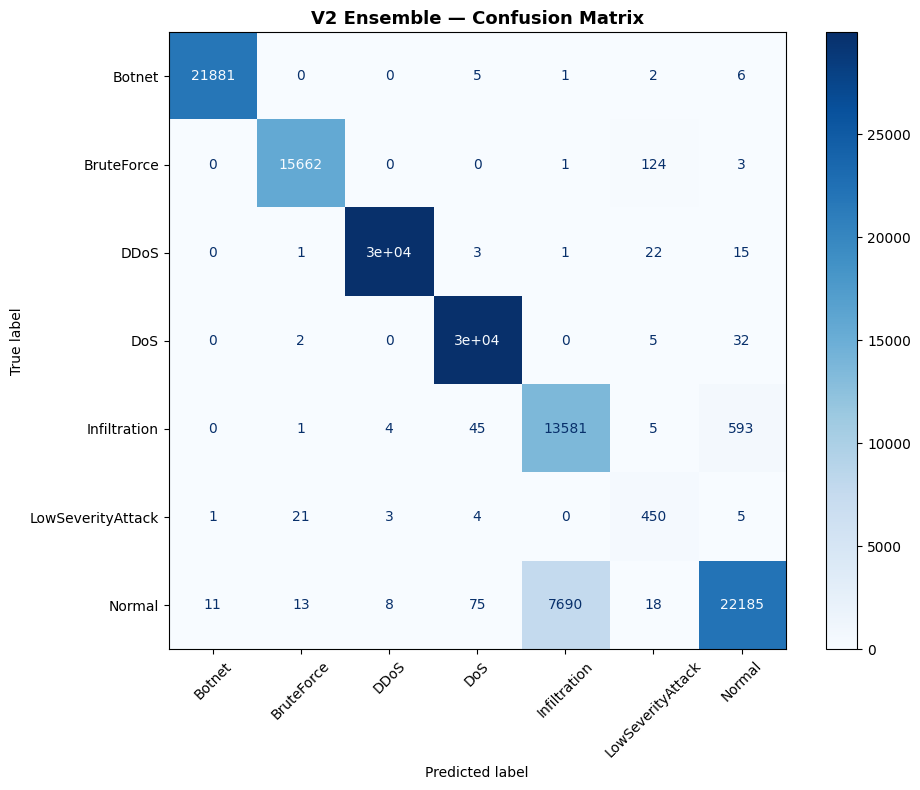

In [15]:
cm = confusion_matrix(y_test, y_pred_final)
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(ax=ax, cmap='Blues', xticks_rotation=45)
ax.set_title('V2 Ensemble — Confusion Matrix', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plots_v2/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Save V2 Artefacts

In [16]:
xgb_model.save_model('XGB_V2_Model.json')
dnn_model.save('dnn_v2_model.keras')
with open('scaler_v2.pkl', 'wb') as f: pickle.dump(scaler, f)
with open('label_encoder_v2.pkl', 'wb') as f: pickle.dump(le, f)
with open('feature_columns_v2.json', 'w') as f: json.dump(kept_features, f)
with open('decision_config_v2.json', 'w') as f:
    json.dump({'class_thresholds': tuned_thresholds, 'ensemble_weights': {'xgb': 0.6, 'dnn': 0.4}}, f, indent=2)
print('V2 artefacts saved.')

V2 artefacts saved.
